In [30]:
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp
from scipy.optimize import root
import matplotlib.pyplot as plt

In [31]:
# Physical constants of the TOV Equations and Energy Conversions
 
import math
import numpy as np


# Fundamental constants in SI
G = 6.67430e-11            # gravitational constant [m^3 kg^-1 s^-2]
c = 2.99792458e8           # speed of light [m s^-1]
hbar = 1.054571817e-34     # reduced Planck constant [J s]
M_sun = 1.98847e30         # solar mass [kg]


# Basic unit conversions

eV_to_J = 1.602176634e-19
MeV_to_J = 1.0e6 * eV_to_J

J_to_eV = 1.0 / eV_to_J
J_to_MeV = 1.0 / MeV_to_J

fm_to_m = 1.0e-15
m_to_fm = 1.0 / fm_to_m

km_to_m = 1.0e3
m_to_km = 1.0 / km_to_m



def kg_to_MeV_c2(m_kg):

    return m_kg * c**2 * J_to_MeV


def MeV_c2_to_kg(m_MeV):

    return m_MeV * MeV_to_J / c**2

MeV_fm3_to_J_m3 = MeV_to_J / fm_to_m**3

J_m3_to_MeV_fm3 = 1.0 / MeV_fm3_to_J_m3

def MeV_fm3_to_SI(x):

    return x * MeV_fm3_to_J_m3


def SI_to_MeV_fm3(x):

    return x * J_m3_to_MeV_fm3


In [32]:
# ============================================================
# Single-polytrope parameters
# ============================================================



In [33]:
Gamma = 2.0

rho_ref = 1.0e18       # kg/m^3
P_ref = 1.0e35         # Pa

rho_ref_cgs = rho_ref / 1000.0

# The numerical value and dimensions of K depend on Gamma.
# Choose K so every EOS passes through the chosen reference point.
K0 = P_ref / (1000.0 * c**2 * rho_ref_cgs**Gamma)

rho_breaks_cgs = np.array([])
Gamma_regions = np.array([Gamma])

N_regions = 1

print("Gamma =", Gamma)
print("K0 =", K0)


Gamma = 2.0
K0 = 1.1126500560536184e-15


In [34]:
# Validate the single-polytrope setup
# IMPORTANT: do not overwrite K0 here; it was calculated above from
# (rho_ref, P_ref, Gamma).

N_regions = len(Gamma_regions)

if len(rho_breaks_cgs) != N_regions - 1:
    raise ValueError("For N regions you need exactly N-1 transition densities.")

if len(rho_breaks_cgs) > 1 and not np.all(np.diff(rho_breaks_cgs) > 0):
    raise ValueError("Transition densities must increase.")

if np.any(Gamma_regions <= 1.0):
    raise ValueError("All Gamma values must be greater than 1.")


In [35]:
# Calculate values for each regions
K_regions = np.zeros(N_regions)
a_regions = np.zeros(N_regions)


K_regions[0] = K0
a_regions[0] = 0.0

# For loop for calculating every value of Ki

for i in range(1, N_regions):
    rho_i = rho_breaks_cgs[i - 1]

    K_regions[i] = (
        K_regions[i - 1]
        * rho_i**(
            Gamma_regions[i - 1]
            - Gamma_regions[i]
        )
    )

    a_regions[i] = (
        a_regions[i - 1]
        + K_regions[i - 1]
        / (Gamma_regions[i - 1] - 1.0)
        * rho_i**(Gamma_regions[i - 1] - 1.0)

        - K_regions[i]
        / (Gamma_regions[i] - 1.0)
        * rho_i**(Gamma_regions[i] - 1.0)
    )

P_breaks_over_c2_cgs = (K_regions[:-1]* rho_breaks_cgs**Gamma_regions[:-1]) # Transition Pressures
P_breaks = (P_breaks_over_c2_cgs* 1000.0* c**2) # Converted to S I Units

def density_region(rho_cgs):
    return np.searchsorted(rho_breaks_cgs,rho_cgs,side="right") # density region identification

def pressure_region(P):
    return np.searchsorted(P_breaks,P,side="right") # pressure region identification

print("N_regions =", N_regions)
print("len(Gamma_regions) =", len(Gamma_regions))
print("len(K_regions) =", len(K_regions))
print("len(a_regions) =", len(a_regions))
print("len(rho_breaks_cgs) =", len(rho_breaks_cgs))



    
    

N_regions = 1
len(Gamma_regions) = 1
len(K_regions) = 1
len(a_regions) = 1
len(rho_breaks_cgs) = 0


In [36]:
#  New EOS that identifies its region i to calculate with relevant K and gamma i , function names are the same as before


def toy_eos(rho):
    rho = np.maximum(rho,0.0)
    rho_cgs = rho / 1000.0
    
    # Determine EOS region
    region = density_region(rho_cgs)
    K = K_regions[region]
    Gamma = Gamma_regions[region]

    P_over_c2_cgs = (K* rho_cgs**Gamma)
    P = (P_over_c2_cgs * 1000.0 * c**2)
    
    return P

#Density Value in EOS
def densityEOS(P):

    P = np.maximum(P, 0.0)

    # Find which EOS region this pressure belongs to
    region = pressure_region(P)

    K = K_regions[region]
    Gamma = Gamma_regions[region]

    # Convert P/c^2 from SI to g/cm^3
    P_over_c2_cgs = P / c**2 / 1000.0

    # Invert:
    # P/c^2 = K rho^Gamma
    rho_cgs = (
        P_over_c2_cgs / K
    )**(1.0 / Gamma)

    # g/cm^3 -> kg/m^3
    rho = rho_cgs * 1000.0

    return rho

def int_energy(P):
    P = np.maximum(P,0.0)
    rho = densityEOS(P)
    rho_cgs = rho / 1000.0

    region = density_region(rho_cgs)
    Gamma = Gamma_regions[region]
    a = a_regions[region]
    epsilon_int = (a* rho* c**2 + P / (Gamma - 1.0))
    return epsilon_int

def e_density(P):

    rho = densityEOS(P)

    epsilon_int = int_energy(P)

    return rho * c**2 + epsilon_int



# EOS normalization check
print("P(rho_ref) =", toy_eos(rho_ref), "Pa")
print("target P_ref =", P_ref, "Pa")
print("relative error =", abs(toy_eos(rho_ref) - P_ref) / P_ref)


P(rho_ref) = 1.0000000000000002e+35 Pa
target P_ref = 1e+35 Pa
relative error = 1.8446744073709552e-16


In [37]:
print("Number of regions =",N_regions)
print()


for i in range(N_regions):
    print(f"Region {i}: "f"Gamma = {Gamma_regions[i]:.6f}, "f"K = {K_regions[i]:.6e}, "f"a = {a_regions[i]:.6e}")


for i in range(N_regions - 1):
    rho_i = rho_breaks_cgs[i]
    P_left = (K_regions[i]* rho_i**Gamma_regions[i])

    P_right = (K_regions[i + 1]* rho_i**Gamma_regions[i + 1])

    print(f"Boundary {i + 1}:")
    print("P_left  =",P_left)
    print("P_right =",P_right)
    print("relative difference =",abs(P_left - P_right) / P_left)
    print()

for i in range(N_regions - 1):
    rho_cgs = rho_breaks_cgs[i]

    rho_SI = (rho_cgs* 1000.0)
    P_over_c2_cgs = (K_regions[i]* rho_cgs**Gamma_regions[i])


    P_SI = (P_over_c2_cgs* 1000.0* c**2)
    E_left = ((1.0 + a_regions[i])* rho_SI * c**2+ P_SI/ (Gamma_regions[i] - 1.0))


    E_right = ((1.0 + a_regions[i + 1])* rho_SI* c**2+ P_SI/ (Gamma_regions[i + 1] - 1.0))
    print(f"Boundary {i + 1}:")
    print("relative energy difference =",abs(E_left - E_right)/ E_left)

Number of regions = 1

Region 0: Gamma = 2.000000, K = 1.112650e-15, a = 0.000000e+00


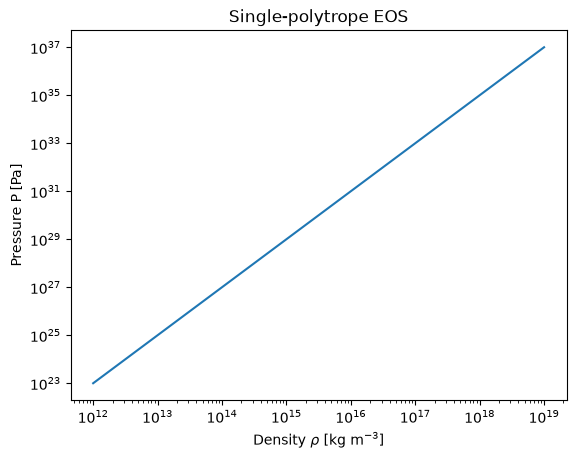

In [38]:
# Plot of EOS
rho_plot = np.logspace(12,19,1000)
P_plot = toy_eos(rho_plot)
plt.loglog(rho_plot,P_plot)

for rho_i in rho_breaks_cgs:

    plt.axvline(rho_i * 1000.0,linestyle="--")


plt.xlabel(r"Density $\rho$ [kg m$^{-3}$]")
plt.ylabel("Pressure P [Pa]")
plt.title("Single-polytrope EOS")
plt.show()

In [39]:

# Gamma = 2.5
# rho_ref = 1.0e18      
# P_ref = 1.0e34       
# K = P_ref / rho_ref**Gamma



# def toy_eos(rho):

#     rho = np.maximum(rho, 0.0)

#     return K * rho**Gamma



# def densityEOS(P):

#     P = np.maximum(P, 0.0)

#     return (P / K)**(1.0 / Gamma)


# def int_energy(P):

#     P = np.maximum(P, 0.0)

#     return P / (Gamma - 1.0)


# # ============================================================
# # Total energy density
# # ============================================================

# def e_density(P):

#     rho = densityEOS(P)

#     epsilon_int = int_energy(P)

#     return rho * c**2 + epsilon_int
# # we have values for all necessary variants of our toy eos

In [40]:
# # piecewise polytrope equation
# # p0 region 

# Gamma0 = 1.35692395
# K0 = 3.99873692e-8
# a0 = 0.0

# # p1 region
# Gamma1 = 3.00
# rho1_cgs = 1.4172900e14

# # Formula for Gamma 1 
# K1 = K0 * rho1_cgs**(Gamma0 - Gamma1)
# # Formula for integration constant ai
# a1 = (a0 + K0 / (Gamma0 - 1.0)* rho1_cgs**(Gamma0 - 1.0) - K1 / (Gamma1 - 1.0) * rho1_cgs**(Gamma1 - 1.0))

# P1_over_c2_cgs = K0 * rho1_cgs**Gamma0
# # P in pascals
# P1 = (P1_over_c2_cgs* 1000.0* c**2)


# def toy_eos(rho):
#     rho = np.maximum(rho, 0.0)
#     rho_cgs = rho / 1000.0
#     # Calculate P/c^2 in g/cm^3

#     P_over_c2_cgs = np.where(rho_cgs < rho1_cgs,K0 * rho_cgs**Gamma0,K1 * rho_cgs**Gamma1)
#     # Convert to SI pressure [Pa]

#     P = (P_over_c2_cgs* 1000.0* c**2)
#     return P


# def densityEOS(P):
#     P = np.maximum(P, 0.0)
#     # Convert P/c^2 into g/cm^3

#     P_over_c2_cgs = (P / c**2 / 1000.0)


#     # Invert the appropriate branch
#     #if P < P1:
#     #use low-density EOS branch
#     #else:
#     #use high-density EOS branch

#     rho_cgs = np.where(P < P1,(P_over_c2_cgs / K0)**(1.0 / Gamma0),(P_over_c2_cgs / K1)**(1.0 / Gamma1))


#     # Convert back to kg/m^3

#     return rho_cgs * 1000.0


# # ============================================================
# # Internal energy density
# # ============================================================

# def int_energy(P):
#     P = np.maximum(P, 0.0)
#     rho = densityEOS(P)
    

#     low_density = rho < rho1_cgs * 1000.0
#     Gamma = np.where(low_density,Gamma0,Gamma1)
#     a = np.where(low_density,a0,a1)
#     epsilon_int = (a * rho * c**2+ P / (Gamma - 1.0))
#     return epsilon_int


# # Total energy density


# def e_density(P):


#     rho = densityEOS(P)
#     epsilon_int = int_energy(P)
#     return (rho * c**2 + epsilon_int)


# print("K0 =", K0)
# print("Gamma0 =", Gamma0)
# print("a0 =", a0)
# print()
# print("K1 =", K1)
# print("Gamma1 =", Gamma1)
# print("a1 =", a1)


# print()


# print("Transition density =",rho1_cgs,"g/cm^3")
# # Numerical value of P1
# print("Transition pressure =",P1,"Pa")


In [41]:
# TOV Equations
def tov_equations(r,y):
    m,P = y
    if r <= 0.0:
        print("TOV equations cannot be evaluated at singularity.")

    if P <= 0.0:

        return [0.0, 0.0]
    E = e_density(P)
    
    dmdr = 4.0 * np.pi * r**2 * E/ c**2
    t1 = G * E * m / (c**2 * r**2)

    t2 = 1.0 + P / E

    t3 = 1.0 + (4.0 * np.pi * r**3 * P) / (m * c**2)

    t4 = 1.0 - (2.0 * G * m) / (c**2 * r)

    dPdr = -t1 * t2 * t3 / t4
    return [dmdr, dPdr]

In [42]:
#Boundary Conditions: Sueface of the Neutron Star

# Stellar surface: P(R) = 0

r_max = 5.0e4
def surface_event(r, y):
    m, P = y

    return P

surface_event.terminal = True


surface_event.direction = -1
rho_c = 1.0e18

# ============================================================
def solve_star(rho_c,r_start=1.0e-3,r_max=5.0e4,rtol=1.0e-7,atol = [1.0e-6, 1.0e18],max_step=500.0):
    r_centre = 0.0
    m_centre = 0.0
    rho_centre = rho_c
    P_c = toy_eos(rho_c)


    # Central total energy density

    E_c = e_density(P_c)


    
    # we start numerical integration at a tiny small r expansion
    m_start = ((4.0 * np.pi / 3.0)* r_start **3 * E_c / c**2)
    # P(r_start) ≈ P_c

    P_start = P_c
    y_start = [m_start,P_start]
    # 
    solution = solve_ivp(tov_equations, t_span=(r_start, r_max), y0=y_start, events=surface_event, rtol=rtol, atol=atol, max_step=max_step)
    if not solution.success:
        raise RuntimeError(solution.message)
    if solution.t_events[0].size == 0:
        raise RuntimeError("The integration did not reach P = 0. ""Increase r_max or check the EOS.")


    R = solution.t_events[0][0]

    M = solution.y_events[0][0][0]
    P_surface = 0.0
    rho_surface = densityEOS(P_surface)
    E_surface = e_density(P_surface)


    return (solution,R,M,P_c,E_c,rho_surface,E_surface)

solution, R, M, P_c, E_c, rho_surface, E_surface = solve_star(rho_c)
print(R)
print(M)
print(P_c)
print(E_c)
print(rho_surface) # 0
print(E_surface) # 0

20808.678851980232
6.932453330966217e+30
1.0000000000000002e+35
1.8987551787368177e+35
0.0
0.0


In [43]:
# ============================================================
#Construct the complete stellar profile

# Numerical solution returned by solve_ivp

r_internal = solution.t
m_internal = solution.y[0]
P_internal = solution.y[1]

r_profile = np.concatenate(([0.0], r_internal))
m_profile = np.concatenate(([0.0], m_internal))
P_profile = np.concatenate(([P_c], P_internal))


r_profile[-1] = R
m_profile[-1] = M
P_profile[-1] = 0.0


rho_profile = densityEOS(P_profile)
epsilon_internal_profile = int_energy(P_profile)
E_profile = e_density(P_profile)



print("CENTRE")
print("------")

print("r =", r_profile[0], "m")
print("m =", m_profile[0], "kg")
print("rho =", rho_profile[0], "kg/m^3")
print("P =", P_profile[0], "Pa")
print("E =", E_profile[0], "J/m^3")


print("SURFACE")
print("-------")

print("R =", r_profile[-1] / 1000.0, "km")
print("M =", m_profile[-1] / M_sun, "M_sun")
print("rho =", rho_profile[-1], "kg/m^3")
print("P =", P_profile[-1], "Pa")

#Converting energy quantities to nuclear units


P_profile_MeV = SI_to_MeV_fm3(P_profile)
E_profile_MeV = SI_to_MeV_fm3(E_profile)
epsilon_internal_MeV = SI_to_MeV_fm3(epsilon_internal_profile)

CENTRE
------
r = 0.0 m
m = 0.0 kg
rho = 1.0000000000000001e+18 kg/m^3
P = 1.0000000000000002e+35 Pa
E = 1.8987551787368177e+35 J/m^3
SURFACE
-------
R = 20.808678851980233 km
M = 3.486325331016418 M_sun
rho = 0.0 kg/m^3
P = 0.0 Pa


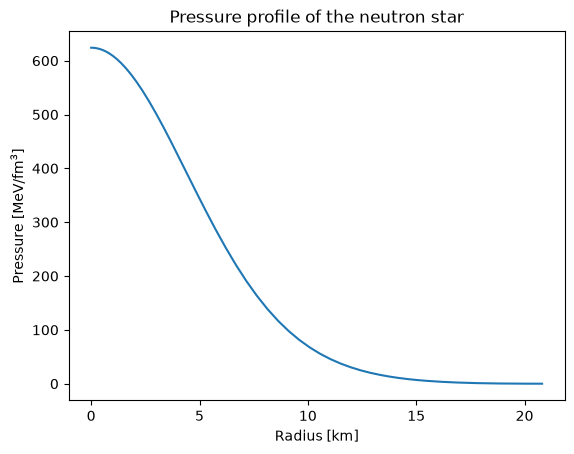

In [44]:
# Plotting the pressure profile wrt radius to surface
plt.plot(r_profile / 1000.0,P_profile_MeV)
plt.xlabel("Radius [km]")
plt.ylabel(r"Pressure [MeV/fm$^3$]")
plt.title("Pressure profile of the neutron star")
plt.show()

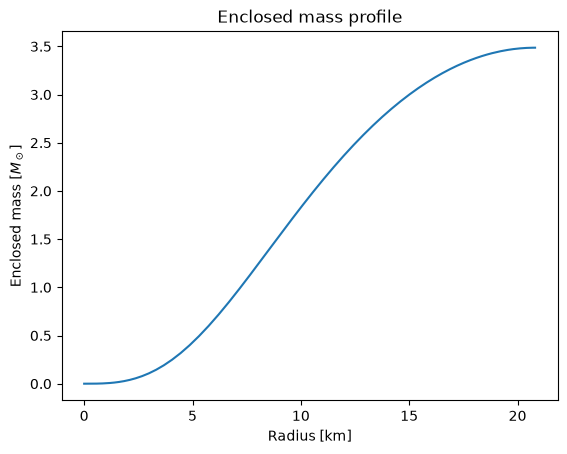

In [45]:

#Plot of enclosed mass from core to sueface
plt.plot(r_profile / 1000.0,m_profile / M_sun)
plt.xlabel("Radius [km]")
plt.ylabel(r"Enclosed mass [$M_\odot$]")
plt.title("Enclosed mass profile")
plt.show()

In [46]:

#Generate a sequence of neutron stars


rho_c_values = np.logspace(np.log10(1.0e17),np.log10(6.0e18),250)

masses = []
radii = []
successful_rho_c = []
for rho_c_trial in rho_c_values:

    try:

        (
            solution_trial,
            R_trial,
            M_trial,
            P_c_trial,
            E_c_trial,
            rho_surface_trial,
            E_surface_trial

        ) = solve_star(
            rho_c_trial
        )


        radii.append(
            R_trial / 1000.0
        )

        masses.append(
            M_trial / M_sun
        )

        successful_rho_c.append(
            rho_c_trial
        )


    except RuntimeError:

        continue
radii = np.array(radii)

masses = np.array(masses)

successful_rho_c = np.array(successful_rho_c)


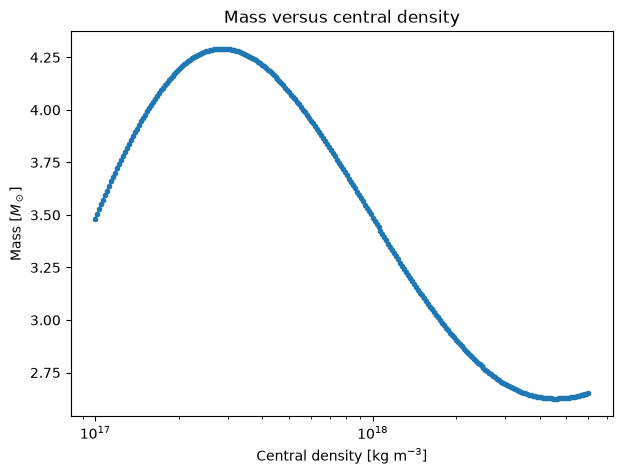

In [47]:
plt.figure(figsize=(7, 5))
plt.plot(successful_rho_c,masses,marker=".")
plt.xscale("log")
plt.xlabel(r"Central density [kg m$^{-3}$]")
plt.ylabel(r"Mass [$M_\odot$]")
plt.title("Mass versus central density")
plt.show()

In [48]:

i_max = np.argmax(masses)
M_max = masses[i_max]
R_at_Mmax = radii[i_max]
rho_c_at_Mmax = successful_rho_c[i_max]


print("Maximum mass =",M_max,"Solar Masses")
print("Radius at maximum mass =",R_at_Mmax,"km")
print("Central density at maximum mass =",rho_c_at_Mmax,"kg/m^3")
XX = SI_to_MeV_fm3(rho_c_at_Mmax * c**2)
print(XX, 'MeV/fm^3 of rest-mass energy density')

Maximum mass = 4.291761209634753 Solar Masses
Radius at maximum mass = 29.541487662085256 km
Central density at maximum mass = 2.8644078782462688e+17 kg/m^3
160.68149790457963 MeV/fm^3 of rest-mass energy density


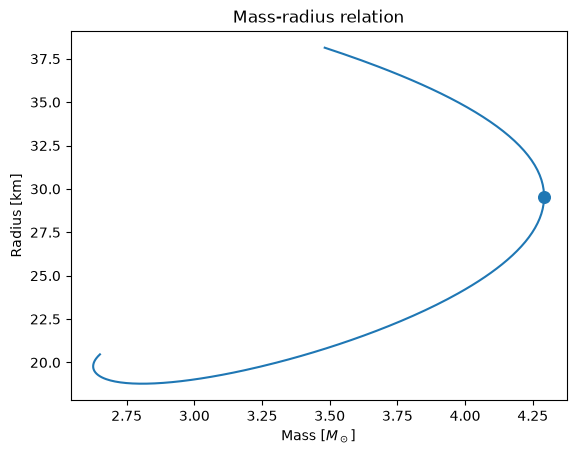

In [49]:
plt.plot(masses,radii)
 
plt.scatter(M_max,R_at_Mmax,s=70,label=(f"Maximum mass = "f"{M_max:.3f} $M_\\odot$"))
plt.xlabel(r"Mass [$M_\odot$]")

plt.ylabel("Radius [km]")
plt.title("Mass-radius relation")


plt.show()











MOST COMPACT CONFIGURATION IN FULL SEQUENCE
-----------------
Maximum compactness = 0.24853860175575868
Mass = 3.672665297571993 M_sun
Radius = 21.820809692831588 km
Central density = 8.20483249295936e+17 kg/m^3


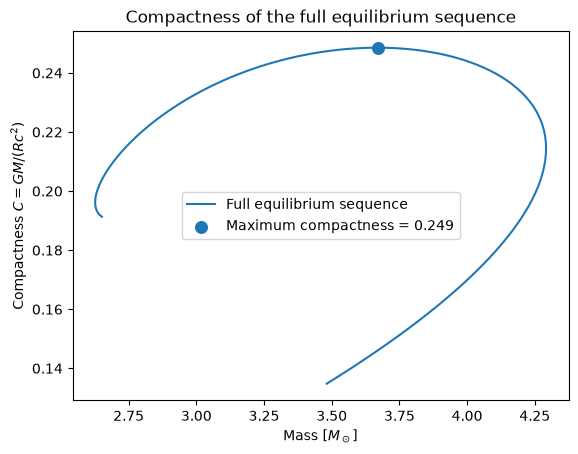

In [50]:
# Plot cof compactness C = GM/Rc^2

M_values_kg = masses * M_sun
R_values_m = radii * 1000.0

compactness = (G * M_values_kg / (R_values_m * c**2))


i_most_compact = np.argmax(compactness)

C_max = compactness[i_most_compact]
M_at_Cmax = masses[i_most_compact]
R_at_Cmax = radii[i_most_compact]
rho_c_at_Cmax = successful_rho_c[i_most_compact]



print("MOST COMPACT CONFIGURATION IN FULL SEQUENCE")
print("-----------------")

print("Maximum compactness =", C_max)
print("Mass =",M_at_Cmax,"M_sun")
print("Radius =",R_at_Cmax,"km")
print("Central density =",rho_c_at_Cmax,"kg/m^3")


plt.plot(masses,compactness,label="Full equilibrium sequence")


# Mark most compact star
plt.scatter(M_at_Cmax,C_max,s=70,label=(f"Maximum compactness = {C_max:.3f}"))


plt.xlabel(r"Mass [$M_\odot$]")
plt.ylabel(r"Compactness $C = GM/(Rc^2)$")

plt.title("Compactness of the full equilibrium sequence")
plt.legend()
plt.show()

In [51]:
def set_single_polytrope(K, gamma):
    global K0, Gamma
    global K_regions, Gamma_regions
    global a_regions
    global rho_breaks_cgs, P_breaks
    global N_regions

    K0 = float(K)
    Gamma = float(gamma)

    # One region only
    rho_breaks_cgs = np.array([])
    P_breaks = np.array([])

    Gamma_regions = np.array([Gamma])
    K_regions = np.array([K0])
    a_regions = np.array([0.0])

    N_regions = 1

set_single_polytrope(K=1.11265e-15,gamma=2.0)

In [58]:
def maximum_stable_compactness(K,gamma,rho_min=1.0e17,rho_max=6.0e18,N=80):

    set_single_polytrope(K,gamma)

    # Expand the density range if the maximum mass
    # lies at either end of the sequence
    for attempt in range(5):

        rho_values=np.logspace(np.log10(rho_min),np.log10(rho_max),N)

        masses=[]
        radii=[]
        densities=[]

        for rho_c in rho_values:

            try:
                solution,R,M,Pc,Ec,_,_=solve_star(rho_c,r_max=2.0e5)

                masses.append(M/M_sun)
                radii.append(R/1000.0)
                densities.append(rho_c)

            except RuntimeError:
                pass

        masses=np.array(masses)
        radii=np.array(radii)
        densities=np.array(densities)

        if len(masses)<5:
            raise RuntimeError("Too few successful stellar models.")

        # First maximum mass = end of stable branch
        i_Mmax=np.argmax(masses)

        # Maximum occurred at lower boundary
        if i_Mmax==0:
            rho_min/=10.0
            continue

        # Maximum occurred at upper boundary
        if i_Mmax==len(masses)-1:
            rho_max*=10.0
            continue

        break

    else:
        raise RuntimeError("Could not bracket the maximum-mass star.")

    # Keep stable branch only
    masses_stable=masses[:i_Mmax+1]
    radii_stable=radii[:i_Mmax+1]
    rho_stable=densities[:i_Mmax+1]

    # C = GM/(Rc^2)
    compactness=(
        G*masses_stable*M_sun/
        (radii_stable*1000.0*c**2)
    )

    i_Cmax=np.argmax(compactness)

    Cmax=compactness[i_Cmax]
    M_Cmax=masses_stable[i_Cmax]
    R_Cmax=radii_stable[i_Cmax]
    rho_Cmax=rho_stable[i_Cmax]

    # Sound speed at centre of most compact stable star
    Pc=toy_eos(rho_Cmax)
    Ec=e_density(Pc)

    cs2_over_c2=gamma*Pc/(Ec+Pc)

    return {
        "K":K,
        "Gamma":gamma,
        "Cmax":Cmax,
        "M_at_Cmax":M_Cmax,
        "R_at_Cmax":R_Cmax,
        "rho_c_at_Cmax":rho_Cmax,
        "cs2_over_c2":cs2_over_c2,
        "causal":cs2_over_c2<=1.0
    }

In [53]:
result = maximum_stable_compactness(K=1.11265e-15,gamma=2.0)
result

{'K': 1.11265e-15,
 'Gamma': 2.0,
 'Cmax': np.float64(0.21443870077952462),
 'M_at_Cmax': np.float64(4.291762845469178),
 'R_at_Cmax': np.float64(29.553975527596993),
 'rho_c_at_Cmax': np.float64(2.8601945066663165e+17),
 'cs2_over_c2': np.float64(0.38893200038986686),
 'causal': np.True_}

In [54]:
rho_ref = 1.0e18
P_ref = 1.0e35

rho_ref_cgs = rho_ref / 1000.0

def K_reference(gamma):

    return (P_ref /(1000.0* c**2* rho_ref_cgs**gamma))

In [55]:
gamma_values = np.array([1.4,1.5,1.6,1.8,2.0])
K_multipliers = np.array([0.3,0.5,1.0,2.0,3.0])
import pandas as pd

grid_start = perf_counter()
results = []

for gamma in gamma_values:

    Kref = K_reference(gamma)

    for multiplier in K_multipliers:
        K = multiplier * Kref

        print(f"Gamma={gamma:.2f}, "f"K/Kref={multiplier:.2f}")
        try:
            result = maximum_stable_compactness(K,gamma)
            result["K_over_Kref"] = multiplier
            result["Kref"] = Kref
            results.append(result)
        except RuntimeError as error:
            print("Failed:", error)
results_df = pd.DataFrame(results)
grid_seconds = perf_counter() - grid_start
print(f"Completed {len(results_df)} parameter combinations in {grid_seconds:.2f} s.")
display(results_df[["Gamma","K_over_Kref","K","Cmax","M_at_Cmax","R_at_Cmax","rho_c_at_Cmax","cs2_over_c2","causal"]])



Gamma=1.40, K/Kref=0.30
Gamma=1.40, K/Kref=0.50
Gamma=1.40, K/Kref=1.00
Gamma=1.40, K/Kref=2.00
Gamma=1.40, K/Kref=3.00
Gamma=1.50, K/Kref=0.30
Gamma=1.50, K/Kref=0.50
Gamma=1.50, K/Kref=1.00
Gamma=1.50, K/Kref=2.00
Gamma=1.50, K/Kref=3.00
Gamma=1.60, K/Kref=0.30
Gamma=1.60, K/Kref=0.50
Gamma=1.60, K/Kref=1.00
Gamma=1.60, K/Kref=2.00
Gamma=1.60, K/Kref=3.00
Gamma=1.80, K/Kref=0.30
Gamma=1.80, K/Kref=0.50
Gamma=1.80, K/Kref=1.00
Gamma=1.80, K/Kref=2.00
Gamma=1.80, K/Kref=3.00
Gamma=2.00, K/Kref=0.30
Gamma=2.00, K/Kref=0.50
Gamma=2.00, K/Kref=1.00
Gamma=2.00, K/Kref=2.00
Gamma=2.00, K/Kref=3.00
Completed 25 parameter combinations in 19.65 s.


,Gamma,K_over_Kref,K,Cmax,M_at_Cmax,R_at_Cmax,rho_c_at_Cmax,cs2_over_c2,causal
0,1.4,0.3,3.337950e-07,0.030432,7.844843,380.661021,1.827742e+15,0.034310,True
1,1.4,0.5,5.563250e-07,0.030432,14.855771,720.857374,5.096745e+14,0.034310,True
2,1.4,1.0,1.112650e-06,0.030432,35.333178,1714.497437,9.009857e+13,0.034310,True
3,1.4,2.0,2.225300e-06,0.030432,84.036932,4077.785102,1.592733e+13,0.034310,True
4,1.4,3.0,3.337950e-06,0.030432,139.503230,6769.216567,5.779826e+12,0.034310,True
5,1.5,0.3,1.055553e-08,0.074244,4.275832,85.043366,4.530088e+16,0.087845,True
6,1.5,0.5,1.759254e-08,0.074244,7.126386,141.738943,1.630832e+16,0.087845,True
7,1.5,1.0,3.518508e-08,0.074244,14.252773,283.477886,4.077079e+15,0.087845,True
8,1.5,2.0,7.037017e-08,0.074244,28.505546,566.955771,1.019270e+15,0.087845,True
9,1.5,3.0,1.055553e-07,0.074244,42.758318,850.433657,4.530088e+14,0.087845,True


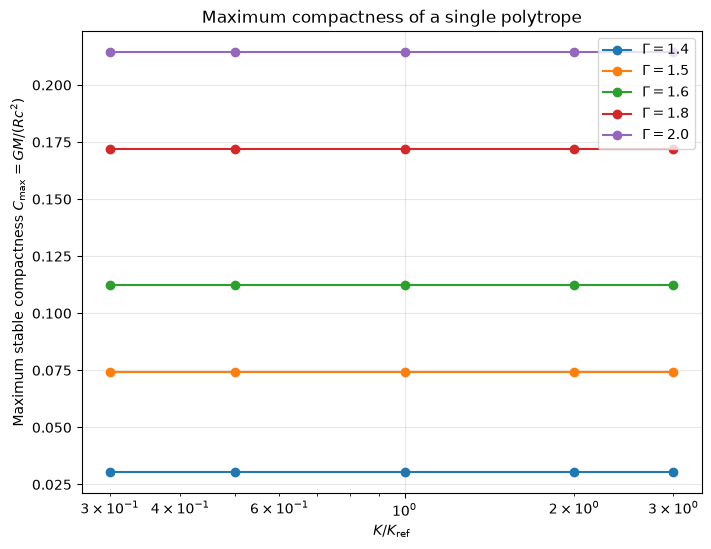

In [56]:
plt.figure(figsize=(8, 6))

for gamma in gamma_values:

    subset = results_df[
        results_df["Gamma"] == gamma
    ]

    plt.plot(
        subset["K_over_Kref"],
        subset["Cmax"],
        marker="o",
        label=fr"$\Gamma={gamma}$"
    )

plt.xscale("log")

plt.xlabel(r"$K/K_{\rm ref}$")
plt.ylabel(
    r"Maximum stable compactness "
    r"$C_{\max}=GM/(Rc^2)$"
)

plt.title(
    "Maximum compactness of a single polytrope"
)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

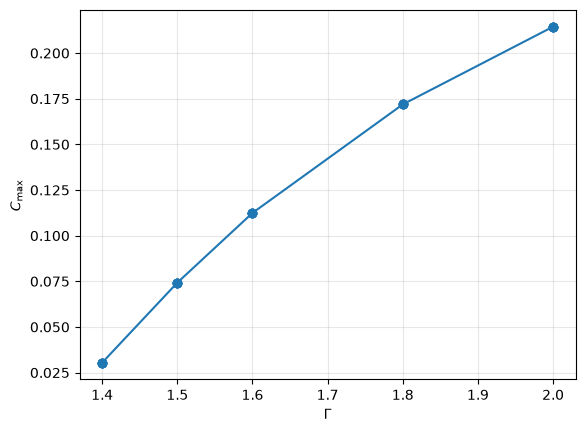

In [57]:
plt.plot(
    results_df["Gamma"],
    results_df["Cmax"],
    "o-"
)

plt.xlabel(r"$\Gamma$")
plt.ylabel(r"$C_{\max}$")
plt.grid(alpha=0.3)
plt.show()